# e03 - Graph Analytics Results and Insight

**Purpose.** Evaluate and interpret notebook g01. Three graphs were built:

| graph | nodes | edges |
| --- | --- | --- |
| grid graph | 9,333 cells of 1 km | cells sharing a side (rook), weighted by similarity of the 14 drivers |
| crop overlap graph | 10 crops | Jaccard overlap of suitable land (≥ 0.05) |
| crop nesting graph | crops with suitable land | A → B when ≥ 95 % of A's suitable land is also suitable for B |

and analysed with connected components (contiguous suitable patches), articulation points (bottleneck cells), Louvain
community detection (agro-ecological communities), label propagation and transitive reduction, in NetworkX and
again in GraphFrames (Spark). This notebook re-checks the key numbers from the saved node table and summarises the
insight. Reads `results/g01_*.csv` and `datasets/processed/experiments/g01_nodes.parquet`; runs in seconds.

In [1]:
import sys
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

import exp_lib as E

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
R = lambda name: pd.read_csv(E.RESULTS_DIR / f"{name}.csv")   # result tables written by the experiment notebooks
CROP_NAMES = {"rice": "Rice", "maize": "Maize", "cassava": "Cassava", "soybean": "Soybean", "oilpalm": "Oil palm",
              "rubber": "Rubber", "sugarcane": "Sugarcane", "coffee": "Coffee", "cacao": "Cacao", "coconut": "Coconut"}
MODEL_NAMES = {"et": "ExtraTrees", "xgb": "XGBoost", "hgb": "HistGB", "knn": "kNN", "ridge": "Ridge",
               "dummy": "Mean baseline", "logreg": "Logistic reg."}
import networkx as nx
from sklearn.metrics import normalized_mutual_info_score

## 1. Graph structure

In [2]:
summary = R("g01_graph_summary")
summary

,measure,value
0,nodes (1 km cells),9333
1,edges (shared cell sides),18156
2,mean degree,3.890710382513661
3,connected components (land masses),10
4,cells on the largest land mass,9171
5,cells on the other land masses,162
6,Louvain communities,77
7,modularity,0.9457506774986386
8,NMI community vs recommended crop,0.26561638294084244
9,NMI community vs land cover,0.18295799330515458


In [3]:
nodes = pd.read_parquet(E.OOF_DIR / "g01_nodes.parquet").merge(
    E.load_table(complete=False)[["grid_id", "lon", "lat", "landcover_majority"]], on="grid_id", validate="1:1")
# Re-check the NMI values reported by g01 from the saved node table.
check = pd.DataFrame({
    "measure": ["NMI community vs recommended crop", "NMI community vs land cover"],
    "g01": [summary.set_index("measure").loc[m, "value"] for m in ["NMI community vs recommended crop", "NMI community vs land cover"]],
    "recomputed": [normalized_mutual_info_score(nodes["community"], nodes["label"]),
                   normalized_mutual_info_score(nodes["community"], nodes["landcover_majority"])]})
check["value g01"] = check.pop("g01").astype(float)
check

,measure,recomputed,value g01
0,NMI community vs recommended crop,0.265616,0.265616
1,NMI community vs land cover,0.182958,0.182958


## 2. Contiguous suitable land per crop (connected components, articulation points)

,crop,suitable km2,patches,largest patch km2,share in largest patch,share in patches >= 25 km2,single-cell patches,share of cells on a patch edge,bottleneck cells in largest patch
0,Rice,2181,48,1828,0.838,0.939,16,0.231,38
1,Maize,8,4,3,0.375,0.000,1,0.875,1
2,Cassava,3060,68,2015,0.658,0.917,22,0.279,25
3,Soybean,256,25,112,0.438,0.680,9,0.629,14
4,Oil palm,3938,64,3443,0.874,0.931,17,0.262,73
5,Rubber,0,0,0,NaN,NaN,0,0.000,0
6,Sugarcane,1186,35,1005,0.847,0.894,17,0.309,35
7,Coffee,3110,67,2126,0.684,0.899,17,0.286,28
8,Cacao,2508,65,1834,0.731,0.917,24,0.315,51
9,Coconut,2890,60,2006,0.694,0.908,20,0.257,18


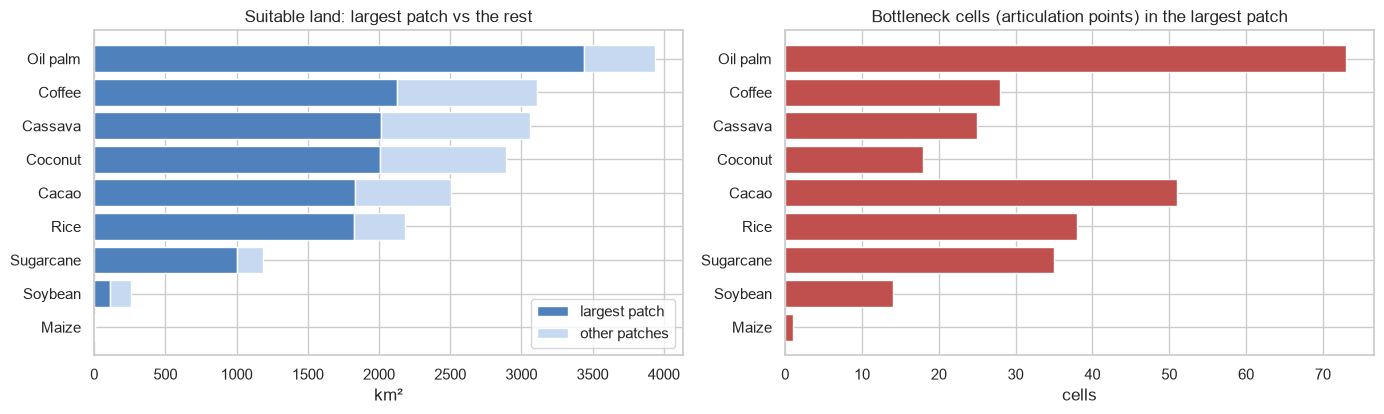

In [4]:
patches = R("g01_patches")
display(patches.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
p = patches[patches["suitable km2"] > 0].sort_values("suitable km2")
ax[0].barh(p["crop"], p["suitable km2"] * p["share in largest patch"], label="largest patch", color="#4f81bd")
ax[0].barh(p["crop"], p["suitable km2"] * (1 - p["share in largest patch"]), left=p["suitable km2"] * p["share in largest patch"],
           label="other patches", color="#c6d9f1")
ax[0].set(title="Suitable land: largest patch vs the rest", xlabel="km²"); ax[0].legend()
ax[1].barh(p["crop"], p["bottleneck cells in largest patch"], color="#c0504d")
ax[1].set(title="Bottleneck cells (articulation points) in the largest patch", xlabel="cells")
fig.tight_layout()
E.save_fig(fig, "e03_patches");

**Reading.** Suitable land is concentrated: for rice, oil palm and sugarcane more than 83 % lies in one contiguous
patch, so a single development area can serve most of the potential. Maize (8 km²) and soybean are fragmented
into small patches (high edge share), which makes them poor candidates for large-scale programmes. Rubber has no
suitable cell at the 5,000 threshold. Bottleneck cells are single cells whose conversion (e.g. to built-up land) would
split the largest patch in two; they are the cells to protect first.

## 3. Contiguous blocks of the same recommended crop

In [5]:
R("g01_label_blocks").round(3)

,recommended crop,cells,blocks,largest block km2,mean block km2,share in blocks >= 25 km2
0,Coffee,954,104,383,9.173,0.711
1,Coconut,855,49,256,17.449,0.828
2,Oil palm,581,108,99,5.380,0.492
3,Cacao,540,99,91,5.454,0.530
4,Cassava,486,76,121,6.395,0.646
5,Rice,369,49,176,7.531,0.680
6,Soybean,134,11,112,12.182,0.836
7,Sugarcane,131,41,30,3.195,0.229


## 4. Agro-ecological communities (Louvain)

In [6]:
com = R("g01_communities")
display(com.head(12).round(2))
print(f"{len(com)} communities; the 10 largest hold {com.nlargest(10, 'cells')['cells'].sum() / com['cells'].sum():.0%} of the cells;"
      f" median size {com['cells'].median():.0f} cells")
display(com.groupby("most frequent recommendation").agg(communities=("cells", "size"), cells=("cells", "sum"),
                                                         mean_purity=("its share", "mean")).sort_values("cells", ascending=False).round(3))

,community,cells,elevation_m,rainfall_mm,temperature_c,cropland_pct,most frequent recommendation,its share,main land cover
0,1,284,191.83,3451.0,24.61,4.22,Not recommended,0.78,Tree cover
1,2,253,490.12,4145.2,22.48,2.10,Not recommended,1.00,Tree cover
2,3,239,72.82,3166.2,25.67,17.83,Not recommended,0.54,Tree cover
3,4,237,244.05,3685.7,24.42,6.62,Not recommended,0.94,Tree cover
4,5,235,85.33,3293.9,25.45,6.83,Not recommended,0.71,Tree cover
5,6,231,143.97,3121.1,25.00,14.61,Not recommended,0.41,Tree cover
6,7,231,97.54,2405.4,25.69,17.01,Coffee,0.43,Tree cover
7,8,228,117.52,2121.3,25.74,5.06,Not recommended,0.75,Tree cover
8,9,219,314.27,2652.9,24.18,7.81,Not recommended,0.78,Tree cover
9,10,217,39.50,3152.0,25.42,0.07,Not recommended,0.58,Tree cover


77 communities; the 10 largest hold 25% of the cells; median size 129 cells


,communities,cells,mean_purity
most frequent recommendation,,,
Not recommended,49,6336,0.825
Coffee,9,978,0.567
Coconut,8,761,0.643
Cassava,4,446,0.463
Rice,4,435,0.430
Soybean,1,197,0.472
Cacao,1,93,0.624
Oil palm,1,87,0.494


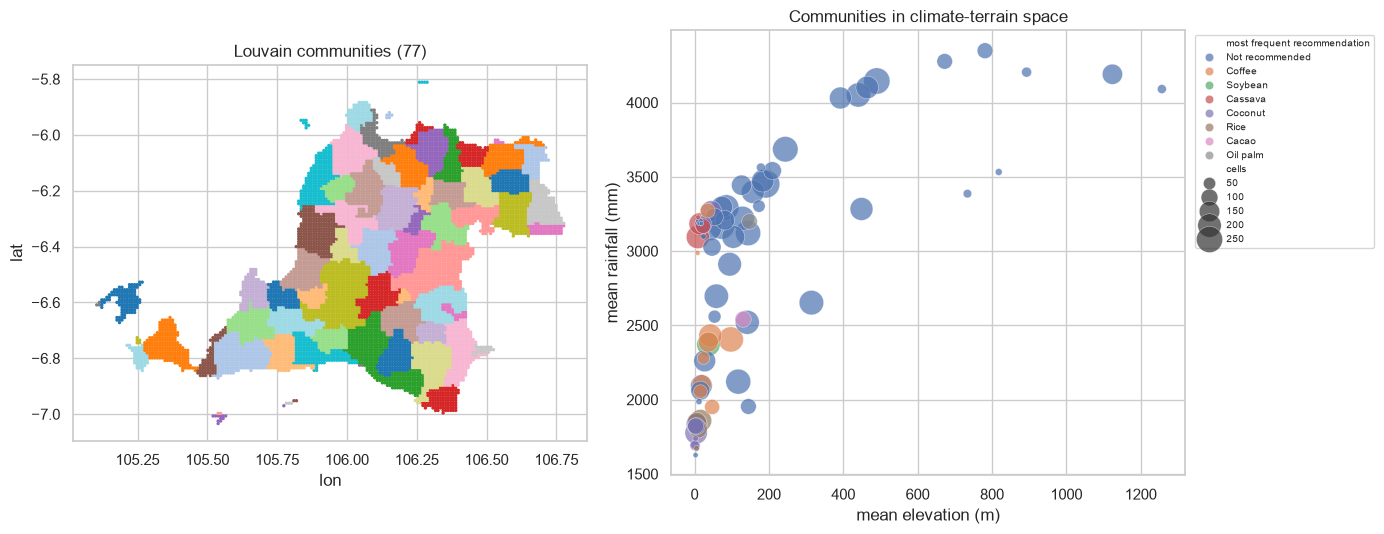

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
codes = nodes["community"].astype("category").cat.codes
rng = np.random.default_rng(0).permutation(codes.max() + 1)
ax[0].scatter(nodes["lon"], nodes["lat"], c=rng[codes], s=2, cmap="tab20")
ax[0].set(title=f"Louvain communities ({nodes['community'].nunique()})", aspect="equal", xlabel="lon", ylabel="lat")
sns.scatterplot(data=com, x="elevation_m", y="rainfall_mm", size="cells", hue="most frequent recommendation", ax=ax[1],
                sizes=(10, 400), alpha=0.7)
ax[1].set(title="Communities in climate-terrain space", xlabel="mean elevation (m)", ylabel="mean rainfall (mm)")
ax[1].legend(fontsize=7, bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
E.save_fig(fig, "e03_communities");

**Reading.** Modularity 0.95 means the communities are sharply separated physical regions. Their NMI with the
recommended crop (0.27) is higher than with land cover (0.18): communities follow the physical drivers that GAEZ is
built from, not the present land use, so they are useful as management zones for extension services.

## 5. Competition and hierarchy between crops (overlap and nesting graphs)

In [8]:
edges = R("g01_crop_graph")
nodes_c = R("g01_crop_nodes")
display(nodes_c.sort_values("competition strength (sum of jaccard)", ascending=False).round(3))
display(R("g01_crop_nesting"))
G = nx.Graph()
G.add_nodes_from(nodes_c["crop"])   # maize and rubber have no overlap edge but stay visible
for _, e in edges[edges["jaccard"] >= 0.05].iterrows():
    G.add_edge(e["crop A"], e["crop B"], weight=e["jaccard"])
H = nx.DiGraph([(r["inner crop"], r["lies within"]) for _, r in R("g01_crop_nesting").iterrows()])
print(f"overlap graph: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges; nesting (Hasse) graph: {H.number_of_edges()} edges")

,crop,suitable km2,competition strength (sum of jaccard),overlap group (Louvain),crops nested inside it,crops it is nested in
2,Cassava,3060,4.292,2,5,1
9,Coconut,2890,4.278,2,4,1
7,Coffee,3110,4.267,2,4,1
0,Rice,2181,4.102,2,3,4
8,Cacao,2508,4.095,2,3,2
4,Oil palm,3938,3.799,2,8,0
6,Sugarcane,1186,2.609,2,1,6
3,Soybean,256,0.657,2,1,6
1,Maize,8,0.000,1,0,8
5,Rubber,0,0.000,3,0,0


,inner crop,lies within,share of inner land
0,Cassava,Oil palm,0.9990
1,Coffee,Oil palm,0.9900
2,Coconut,Oil palm,0.9723
3,Rice,Cassava,0.9954
4,Rice,Coffee,0.9963
5,Rice,Coconut,1.0000
6,Cacao,Cassava,0.9553
7,Soybean,Rice,1.0000
8,Soybean,Cacao,1.0000
9,Sugarcane,Rice,0.9933


overlap graph: 10 nodes, 28 edges; nesting (Hasse) graph: 13 edges


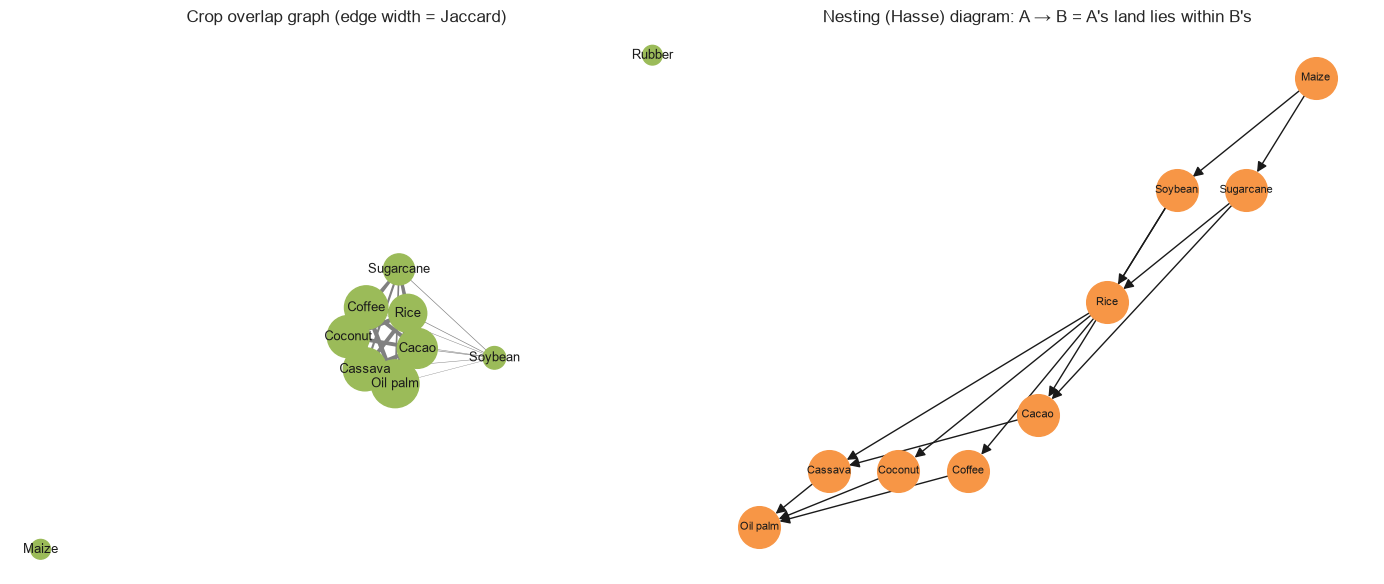

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
pos = nx.spring_layout(G, weight="weight", seed=1)
size = nodes_c.set_index("crop")["suitable km2"]
nx.draw_networkx(G, pos, ax=ax[0], node_size=[200 + size.get(n, 0) / 4 for n in G], node_color="#9bbb59",
                 width=[4 * G[u][v]["weight"] for u, v in G.edges], edge_color="grey", font_size=9)
ax[0].set_title("Crop overlap graph (edge width = Jaccard)"); ax[0].axis("off")
level = {n: len(nx.descendants(H, n)) for n in H}   # how many crops lie above it
posh = {n: (i, level[n]) for i, n in enumerate(sorted(H, key=lambda n: (level[n], n)))}
nx.draw_networkx(H, posh, ax=ax[1], node_color="#f79646", node_size=900, font_size=8, arrowsize=15)
ax[1].set_title("Nesting (Hasse) diagram: A → B = A's land lies within B's"); ax[1].axis("off")
fig.tight_layout()
E.save_fig(fig, "e03_crop_graphs");

## 6. NetworkX vs GraphFrames (Spark)

In [10]:
display(R("g01_graphframes_check"))
t = R("g01_graphframes_timings")
t["ratio"] = t["GraphFrames (s)"] / t["NetworkX (s)"]
display(t.round(3))
R("g01_label_propagation")

,check,NetworkX,GraphFrames,equal
0,node degrees (sum),36312,36312,True
1,land masses,10,10,True
2,Rice: patches / largest km2,48 / 1828,48 / 1828,True
3,Maize: patches / largest km2,4 / 3,4 / 3,True
4,Cassava: patches / largest km2,68 / 2015,68 / 2015,True
5,Soybean: patches / largest km2,25 / 112,25 / 112,True
6,Oil palm: patches / largest km2,64 / 3443,64 / 3443,True
7,Rubber: patches / largest km2,0 / 0,0 / 0,True
8,Sugarcane: patches / largest km2,35 / 1005,35 / 1005,True
9,Coffee: patches / largest km2,67 / 2126,67 / 2126,True


,step,NetworkX (s),GraphFrames (s),ratio
0,"start, build the graph",0.029,8.577,295.759
1,node degrees,0.007,1.972,281.714
2,"connected components, whole grid",0.006,39.092,6515.333
3,"connected components, suitable land of 10 crops",0.053,196.060,3699.245
4,"communities (Louvain / label propagation, 20 r...",0.773,2.469,3.194


,rounds,communities,seconds,NMI vs Louvain
0,5,1900,1.7844,0.6646
1,10,1705,1.3769,0.6680
2,20,1687,2.4691,0.6682


**Reading.** All 12 deterministic checks agree exactly, so the distributed implementation is correct. On 9,333
nodes NetworkX is 3-3,700x faster because each GraphFrames step launches Spark jobs (connected components iterates with
checkpoints). Label propagation, the scalable community method of GraphFrames, ignores edge weights and stops at ~1,700
small communities, yet agrees with Louvain at NMI 0.67: it finds the same boundaries at a finer grain.

## 7. Insight summary

1. Suitable land for most crops forms one dominant contiguous patch; a few bottleneck cells keep it connected.
2. Maize and soybean land is fragmented; rubber has none at the 5,000 threshold.
3. 77 agro-ecological communities with modularity 0.95 give natural management zones driven by physical conditions.
4. The crops form three competition groups; oil palm land contains the land of cassava, coffee and coconut, which in
   turn contains rice: choosing oil palm everywhere would compete with almost every other crop.
5. GraphFrames reproduces NetworkX exactly; it is slower at province scale but is the path for national grids.